# Radar rainfall regridding: statistics & conservation checks

Run this on **Mac first**, then on Windows. It compares a source MDV rainfall field with a conservative Cartesian regrid to the target NetCDF grid. Optionally compare against an output NetCDF produced by the full processing script.

**Important:** a conservative regrid preserves the **area-integral of rainfall rate** on a shared projected domain, not necessarily the unweighted sum or mean of pixel values. With partial coverage/missing pixels, full-domain conservation is not guaranteed if values are renormalised over valid overlaps. These tests report coverage explicitly. This method assumes the source and target x/y coordinates share the same projected CRS and units. The notebook does not establish that automatically.

Run cells top to bottom. Change only the paths and settings below first.

In [37]:
from pathlib import Path
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from scipy.sparse import csr_matrix, kron
import pyart

# CHANGE THESE
MDV_FILE = Path("/Users/matthewwright/Downloads/single_precip_sample/20211017/000012.mdv")
TARGET_GRID_FILE = Path('../../data/example_grids/eg_radar_grid.nc')
# Optional: 6-hour output generated by the full processing script (set None to skip)
OUTPUT_6H_FILE = None #Path('/Volumes/Rain/processed_rwandan_radar/6h/2018/20181112_00.nc')
SOURCE_FIELD = 'rate'
OUTPUT_FIELD = 'rainfall_rate'
MIN_VALID_AREA_FRACTION = 0.0
# Tolerance for exact conservation on complete, common-domain synthetic tests
RTOL = 1e-11


## 1. Regridding implementation used for testing

This version supports ascending/descending coordinates and calculates target-cell coverage using **full target cell area**. It does not replace projection verification.

In [38]:
def centres_to_bounds(coord):
    coord = np.asarray(coord, dtype=float)
    if coord.ndim != 1 or len(coord) < 2 or not np.all(np.isfinite(coord)):
        raise ValueError('Expected >=2 finite 1D cell centres')
    delta = np.diff(coord)
    if not (np.all(delta > 0) or np.all(delta < 0)):
        raise ValueError('Coordinates must be strictly monotonic')
    mid = (coord[:-1] + coord[1:]) / 2
    bounds = np.empty(len(coord) + 1)
    bounds[1:-1] = mid
    bounds[0] = coord[0] - (mid[0] - coord[0])
    bounds[-1] = coord[-1] + (coord[-1] - mid[-1])
    return bounds

def overlaps_1d(src, dst):
    src, dst = np.asarray(src, float), np.asarray(dst, float)
    # validate both, including descending coordinates
    centres_to_bounds(src); centres_to_bounds(dst)
    sr, dr = src[0] > src[-1], dst[0] > dst[-1]
    se = centres_to_bounds(src[::-1] if sr else src)
    de = centres_to_bounds(dst[::-1] if dr else dst)
    rows, cols, vals = [], [], []
    i = j = 0
    while i < len(src) and j < len(dst):
        overlap = min(se[i+1], de[j+1]) - max(se[i], de[j])
        if overlap > 0:
            rows.append(len(dst)-1-j if dr else j)
            cols.append(len(src)-1-i if sr else i)
            vals.append(overlap)
        if se[i+1] < de[j+1]: i += 1
        elif de[j+1] < se[i+1]: j += 1
        else: i += 1; j += 1
    return csr_matrix((vals, (rows, cols)), shape=(len(dst), len(src)))

def cell_areas(x, y):
    return np.abs(np.diff(centres_to_bounds(y)))[:, None] * np.abs(np.diff(centres_to_bounds(x)))[None, :]

def weights_2d(sx, sy, tx, ty):
    return kron(overlaps_1d(sy, ty), overlaps_1d(sx, tx), format='csr')

def regrid(data, W, target_areas, min_fraction=0.0):
    a = np.ma.filled(np.ma.asarray(data, dtype=float), np.nan)
    if a.ndim == 2: a = a[None, ...]
    if a.ndim != 3 or W.shape[1] != a.shape[-2]*a.shape[-1]:
        raise ValueError('Expected data shape (time, source_y, source_x)')
    nt = a.shape[0]
    flat = a.reshape(nt, -1)
    valid = np.isfinite(flat)
    numerator = (W @ np.where(valid, flat, 0).T).T
    valid_area = (W @ valid.astype(float).T).T
    full_area = np.asarray(target_areas).ravel()
    if len(full_area) != W.shape[0]: raise ValueError('Wrong target area shape')
    out = np.full_like(numerator, np.nan)
    np.divide(numerator, valid_area, out=out, where=valid_area > 0)
    coverage = np.divide(valid_area, full_area[None, :], out=np.zeros_like(valid_area), where=full_area[None, :] > 0)
    out[coverage < min_fraction] = np.nan
    return out.reshape((nt,) + target_areas.shape), coverage.reshape((nt,) + target_areas.shape)


## 2. Synthetic unit tests (no files needed)

Checks a constant field, area-integral conservation, descending axes, and missing values.

In [39]:
sx = sy = np.array([0.5, 1.5, 2.5, 3.5])
tx = ty = np.array([1., 3.])
W0 = weights_2d(sx, sy, tx, ty)
A0 = cell_areas(tx, ty)
a = np.arange(1., 17.).reshape(1, 4, 4)
b, cover = regrid(a, W0, A0)
np.testing.assert_allclose(b[0], [[3.5, 5.5], [11.5, 13.5]])
np.testing.assert_allclose(np.sum(a * cell_areas(sx, sy)), np.nansum(b * A0), rtol=RTOL)
np.testing.assert_allclose(cover, 1.)
constant, _ = regrid(np.full((1,4,4), 7.), W0, A0)
np.testing.assert_allclose(constant, 7.)
reverse, _ = regrid(a[:, ::-1, ::-1], weights_2d(sx[::-1], sy[::-1], tx[::-1], ty[::-1]), cell_areas(tx[::-1], ty[::-1]))
np.testing.assert_allclose(reverse[:, ::-1, ::-1], b)
missing = a.copy(); missing[0, 0, 0] = np.nan
missing_out, missing_cover = regrid(missing, W0, A0)
assert np.isclose(missing_cover[0, 0, 0], 0.75)
print('PASS: known values, constant field, complete-domain conservation, descending axes, missing-data coverage')


PASS: known values, constant field, complete-domain conservation, descending axes, missing-data coverage


## 3. Read one MDV file and the target grid

The source is an **instantaneous rainfall rate**, so compare it against the regridded version of the same instant. Do not compare it directly to a 6-hour mean and expect identical statistics.

In [40]:
if not MDV_FILE.is_file(): raise FileNotFoundError(MDV_FILE)
if not TARGET_GRID_FILE.is_file(): raise FileNotFoundError(TARGET_GRID_FILE)
radar = pyart.io.read_grid_mdv(MDV_FILE, file_field_names=True)
with xr.open_dataset(TARGET_GRID_FILE) as target:
    tx, ty = target.x.values.copy(), target.y.values.copy()
    target_attrs = dict(target.attrs)
    target_x_attrs = dict(target.x.attrs)
    target_y_attrs = dict(target.y.attrs)
    target_variables = list(target.variables)
sx = np.asarray(radar.point_x['data'][0, 0, :], float)
sy = np.asarray(radar.point_y['data'][0, :, 0], float)
source = np.ma.filled(np.ma.asarray(radar.fields[SOURCE_FIELD]['data'][0], dtype=float), np.nan)
if source.shape != (len(sy), len(sx)):
    raise ValueError(f'Source data shape {source.shape} disagrees with coordinates')
print('Radar projection:', radar.projection)
print('Radar origin (lon,lat):', radar.origin_longitude['data'], radar.origin_latitude['data'])
print('Target dataset attributes:', target_attrs)
print('Target x attributes:', target_x_attrs)
print('Target y attributes:', target_y_attrs)
print('Target variables:', target_variables)
for name, x, y in [('Source', sx, sy), ('Target', tx, ty)]:
    print(f'{name}: shape={(len(y),len(x))}, x=[{x.min():.3f},{x.max():.3f}], y=[{y.min():.3f},{y.max():.3f}], median dx={np.median(np.abs(np.diff(x))):.3f}, median dy={np.median(np.abs(np.diff(y))):.3f}')
print('VERIFY MANUALLY: source and target x/y must use the same projection, origin and units.')


Radar projection: {'proj': 'pyart_aeqd', '_include_lon_0_lat_0': True}
Radar origin (lon,lat): [30.11234093] [-2.15807605]
Target dataset attributes: {}
Target x attributes: {'standard_name': 'projection_x_coordinate', 'long_name': 'x-coordinate in Cartesian system', 'units': 'm', 'axis': 'X'}
Target y attributes: {'standard_name': 'projection_y_coordinate', 'long_name': 'y-coordinate in Cartesian system', 'units': 'm', 'axis': 'Y'}
Target variables: ['qpe', 'central_lon', 'central_lat', 'y', 'x', 'time', 'lon', 'lat']
Source: shape=(800, 800), x=[-199750.000,199750.000], y=[-199750.000,199750.000], median dx=500.000, median dy=500.000
Target: shape=(396, 396), x=[-198000.000,197000.000], y=[-198000.000,197000.000], median dx=1000.000, median dy=1000.000
VERIFY MANUALLY: source and target x/y must use the same projection, origin and units.


## 4. Regrid and summarise rainfall statistics

The table reports min/max, percentiles, unweighted pixel mean, area-weighted mean, valid area and area integral. Means over **different domains** should not be expected to match.

In [44]:
W = weights_2d(sx, sy, tx, ty)
As = cell_areas(sx, sy)
At = cell_areas(tx, ty)
remapped, coverage = regrid(source, W, At, MIN_VALID_AREA_FRACTION)
remapped = remapped[0]
coverage = coverage[0]
# remapped = np.nan_to_num(remapped, nan=0.0)

def stats(label, arr, areas):
    arr = np.asarray(arr, float)
    valid = np.isfinite(arr)
    v = arr[valid]
    return dict(grid=label, cells=arr.size, valid_cells=int(valid.sum()), valid_fraction=float(valid.mean()),
                min=float(np.min(v)) if v.size else np.nan,
                p05=float(np.percentile(v,5)) if v.size else np.nan,
                median=float(np.median(v)) if v.size else np.nan,
                p95=float(np.percentile(v,95)) if v.size else np.nan,
                max=float(np.max(v)) if v.size else np.nan,
                pixel_mean=float(np.mean(v)) if v.size else np.nan,
                area_mean=float(np.sum(arr[valid]*areas[valid])/np.sum(areas[valid])) if v.size else np.nan,
                valid_area=float(np.sum(areas[valid])),
                area_integral=float(np.sum(arr[valid]*areas[valid])) if v.size else np.nan)
summary = pd.DataFrame([stats('Source MDV', source, As), stats('Regridded', remapped, At)]).set_index('grid')
display(summary.T)
print('Target cell valid coverage (min, median, max):', np.min(coverage), np.median(coverage), np.max(coverage))
print('Target cells with no valid overlap:', int(np.sum(coverage == 0)))
print('Target cells with incomplete valid coverage:', int(np.sum(coverage < 1 - 1e-10)))


grid,Source MDV,Regridded
cells,6.400000e+05,1.568160e+05
valid_cells,2.757800e+04,1.031700e+04
valid_fraction,4.309063e-02,6.579048e-02
min,0.000000e+00,0.000000e+00
p05,0.000000e+00,0.000000e+00
median,0.000000e+00,0.000000e+00
p95,1.398733e+00,1.423507e+00
max,9.193552e+01,3.443933e+01
pixel_mean,2.683909e-01,2.823383e-01
area_mean,2.683909e-01,2.823383e-01


Target cell valid coverage (min, median, max): 0.0 0.0 1.0
Target cells with no valid overlap: 146499
Target cells with incomplete valid coverage: 152924


## 5. Conservation on the actual overlapping area

A meaningful conservation check must use the **same spatial support**. The source contribution integral is computed from valid source values weighted by their intersection with target cells. The destination integral uses each target value multiplied by the **valid overlap area**. This identity should hold for any finite values when `MIN_VALID_AREA_FRACTION=0` (aside from floating-point error).

Also shown is the full target-cell-area integral, which can differ for partially covered cells. The comparison does **not** establish spherical-area conservation.

In [45]:
src_flat = source.ravel()
valid_flat = np.isfinite(src_flat)
valid_overlap_area = np.asarray(W @ valid_flat.astype(float)).ravel()
source_overlap_integral = float(np.dot(np.asarray(W.sum(axis=0)).ravel()[valid_flat], src_flat[valid_flat]))
result_flat = remapped.ravel()
keep = np.isfinite(result_flat)
result_valid_overlap_integral = float(np.dot(result_flat[keep], valid_overlap_area[keep]))
result_full_target_integral = float(np.dot(result_flat[keep], At.ravel()[keep]))
absolute_error = result_valid_overlap_integral - source_overlap_integral
relative_error = absolute_error / abs(source_overlap_integral) if source_overlap_integral != 0 else np.nan
print(f'Source integral over source/target intersection: {source_overlap_integral:.12g}')
print(f'Regridded integral weighted by valid overlap:   {result_valid_overlap_integral:.12g}')
print(f'Regridded integral weighted by full target:    {result_full_target_integral:.12g}')
print(f'Absolute difference: {absolute_error:.6g}')
print(f'Relative difference: {relative_error:.3e}')
if MIN_VALID_AREA_FRACTION == 0:
    np.testing.assert_allclose(result_valid_overlap_integral, source_overlap_integral, rtol=RTOL, atol=1e-9)
    print('PASS: valid-overlap area integral conserved')
else:
    print('No strict assertion: coverage threshold may deliberately discard target cells.')


Source integral over source/target intersection: 1840249521.88
Regridded integral weighted by valid overlap:   1840249521.88
Regridded integral weighted by full target:    2912884378.68
Absolute difference: 0
Relative difference: 0.000e+00
PASS: valid-overlap area integral conserved


## 6. Maps and distributions

Plots use projected coordinates. Check for unexpected stripes, offsets, outliers and excessive missing coverage.

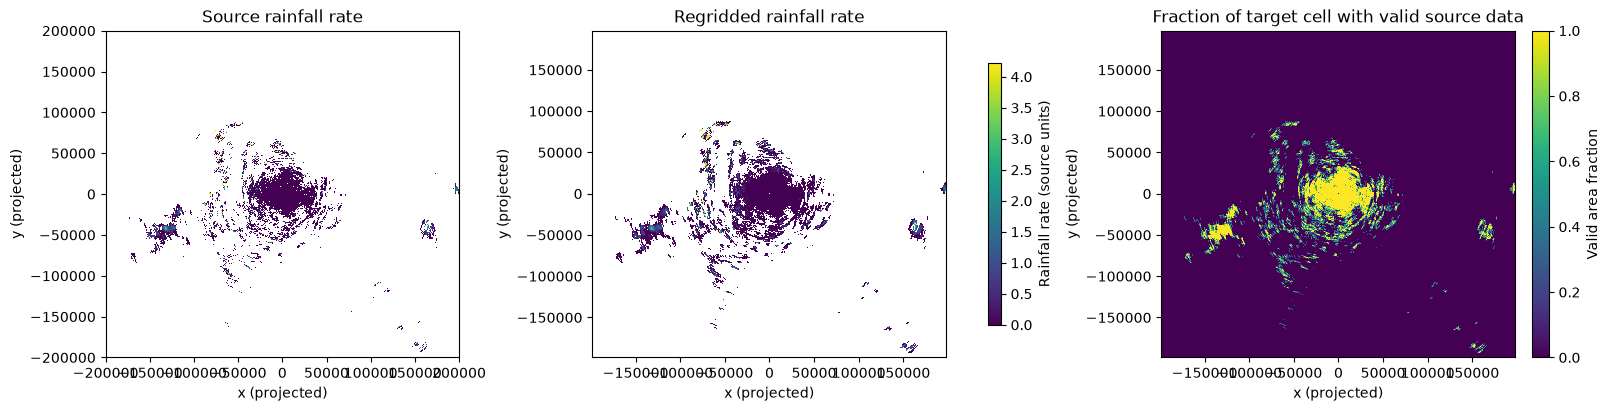

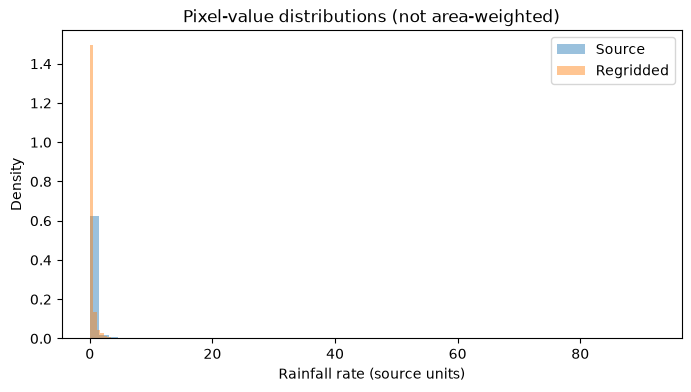

In [46]:
fig, axs = plt.subplots(1, 3, figsize=(16, 4), constrained_layout=True)
finite = np.concatenate([source[np.isfinite(source)], remapped[np.isfinite(remapped)]])
vmax = np.percentile(finite, 99) if finite.size else 1
vmax = max(vmax, 1e-12)
for ax, x, y, field, name in [(axs[0], sx, sy, source, 'Source rainfall rate'), (axs[1], tx, ty, remapped, 'Regridded rainfall rate')]:
    mesh = ax.pcolormesh(centres_to_bounds(x), centres_to_bounds(y), field, shading='auto', vmin=0, vmax=vmax)
    ax.set_title(name); ax.set_xlabel('x (projected)'); ax.set_ylabel('y (projected)')
fig.colorbar(mesh, ax=axs[:2], label='Rainfall rate (source units)', shrink=.8)
mesh2 = axs[2].pcolormesh(centres_to_bounds(tx), centres_to_bounds(ty), coverage, shading='auto', vmin=0, vmax=1, cmap='viridis')
axs[2].set_title('Fraction of target cell with valid source data')
axs[2].set_xlabel('x (projected)'); axs[2].set_ylabel('y (projected)')
fig.colorbar(mesh2, ax=axs[2], label='Valid area fraction')
plt.show()
fig, ax = plt.subplots(figsize=(8, 4))
for values, label in [(source, 'Source'), (remapped, 'Regridded')]:
    v = values[np.isfinite(values)]
    if len(v): ax.hist(v, bins=60, alpha=.45, density=True, label=label)
ax.set_xlabel('Rainfall rate (source units)'); ax.set_ylabel('Density'); ax.legend(); ax.set_title('Pixel-value distributions (not area-weighted)')
plt.show()


## 7. Optional: inspect a full-script 6-hour output

This checks output coordinates and basic statistics. It **cannot** test conservation against a single MDV snapshot because the output is a temporal mean. For an exact 6-hour conservation test, reconstruct the corresponding 6-hour source mean from all MDV scans, then use that mean as the source in Sections 4–6.

<xarray.Dataset> Size: 3MB
Dimensions:           (time: 1, y: 396, x: 396)
Coordinates:
  * time              (time) datetime64[ns] 8B 2018-11-12
  * y                 (y) float64 3kB -1.98e+05 -1.97e+05 ... 1.96e+05 1.97e+05
  * x                 (x) float64 3kB -1.98e+05 -1.97e+05 ... 1.96e+05 1.97e+05
    lon               (y, x) float64 1MB ...
    lat               (y, x) float64 1MB ...
    radar_centre_lon  float64 8B ...
    radar_centre_lat  float64 8B ...
Data variables:
    rainfall_rate     (time, y, x) float32 627kB ...
Attributes:
    regrid_method:  conservative
PASS: output projected coordinates match target grid


grid,6-hour output
cells,1.568160e+05
valid_cells,2.935000e+03
valid_fraction,1.871620e-02
min,0.000000e+00
p05,0.000000e+00
median,0.000000e+00
p95,0.000000e+00
max,0.000000e+00
pixel_mean,0.000000e+00
area_mean,0.000000e+00


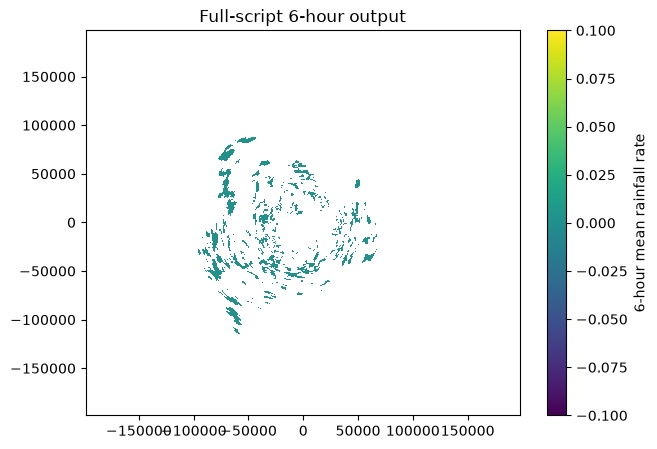

In [ ]:
if OUTPUT_6H_FILE is None:
    print('Skipped: set OUTPUT_6H_FILE to inspect a produced 6-hour NetCDF.')
else:
    output_path = Path(OUTPUT_6H_FILE)
    with xr.open_dataset(output_path) as ds:
        print(ds)
        field = ds[OUTPUT_FIELD]
        if 'time' in field.dims:
            if field.sizes['time'] != 1: raise ValueError('Expected one timestamp in a 6-hour file')
            field = field.isel(time=0)
        out = np.asarray(field.transpose('y', 'x').values, float)
        ox, oy = np.asarray(ds.x.values), np.asarray(ds.y.values)
        np.testing.assert_allclose(ox, tx)
        np.testing.assert_allclose(oy, ty)
        print('PASS: output projected coordinates match target grid')
        display(pd.DataFrame([stats('6-hour output', out, cell_areas(ox, oy))]).set_index('grid').T)
        fig, ax = plt.subplots(figsize=(7,5))
        pcm = ax.pcolormesh(centres_to_bounds(ox), centres_to_bounds(oy), out, shading='auto')
        fig.colorbar(pcm, ax=ax, label='6-hour mean rainfall rate')
        ax.set_title('Full-script 6-hour output'); plt.show()


In [33]:
from pathlib import Path
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

# --------------------------------------------------
# SETTINGS
# --------------------------------------------------

OUT_FOLDER_6H = Path(
    "/Volumes/Rain/processed_rwandan_radar/6h"
)

VAR = "rainfall_rate"

# --------------------------------------------------
# READ ALL 6-HOUR FILES
# --------------------------------------------------

files = sorted(
    f for f in OUT_FOLDER_6H.glob("*/*.nc")
    if not f.name.startswith("._")
)
print(f"Found {len(files)} files")

rain_values = []

total_pixels = 0
total_valid = 0
total_zero = 0
total_positive = 0

for i, f in enumerate(files):

    with xr.open_dataset(f) as ds:
        data = ds[VAR].values.ravel()

    total_pixels += data.size

    valid = data[np.isfinite(data)]

    total_valid += valid.size
    total_zero += np.sum(valid == 0)
    total_positive += np.sum(valid > 0)

    # Only store positive rainfall values for histogram
    rain_values.append(valid[valid > 0])

    if (i + 1) % 100 == 0:
        print(f"Processed {i + 1}/{len(files)} files")

# --------------------------------------------------
# COMBINE VALUES
# --------------------------------------------------

rain_values = (
    np.concatenate(rain_values)
    if rain_values else np.array([])
)

# --------------------------------------------------
# STATISTICS
# --------------------------------------------------

print("\nRAINFALL STATISTICS")
print("----------------------------")
print(f"Total pixels:    {total_pixels:,}")
print(f"Valid pixels:    {total_valid:,}")
print(f"Missing pixels:  {total_pixels - total_valid:,}")
print(f"Zero pixels:     {total_zero:,}")
print(f"Positive pixels: {total_positive:,}")

if total_valid:
    print(f"Fraction positive among valid: {100 * total_positive / total_valid:.3f}%")

if rain_values.size:
    print(f"\nMinimum positive: {rain_values.min():.6f}")
    print(f"Mean positive:    {rain_values.mean():.6f}")
    print(f"Median positive:  {np.median(rain_values):.6f}")
    print(f"95th percentile:  {np.percentile(rain_values, 95):.6f}")
    print(f"99th percentile:  {np.percentile(rain_values, 99):.6f}")
    print(f"Maximum:          {rain_values.max():.6f}")

# --------------------------------------------------
# HISTOGRAM
# --------------------------------------------------

if rain_values.size:

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    # Linear histogram
    axes[0].hist(
        rain_values,
        bins=100,
        color="steelblue",
        edgecolor="none"
    )

    axes[0].set_xlabel("Rainfall rate (mm/h)")
    axes[0].set_ylabel("Pixel count")
    axes[0].set_title("Positive rainfall — linear scale")

    # Logarithmic histogram
    log_bins = np.logspace(
        np.log10(rain_values.min()),
        np.log10(rain_values.max()),
        100
    )

    axes[1].hist(
        rain_values,
        bins=log_bins,
        color="steelblue",
        edgecolor="none"
    )

    axes[1].set_xscale("log")
    axes[1].set_yscale("log")
    axes[1].set_xlabel("Rainfall rate (mm/h)")
    axes[1].set_ylabel("Pixel count")
    axes[1].set_title("Positive rainfall — log scale")

    plt.tight_layout()
    plt.show()

else:
    print("\nNo positive rainfall values found.")

Found 246 files
Processed 100/246 files
Processed 200/246 files

RAINFALL STATISTICS
----------------------------
Total pixels:    38,576,736
Valid pixels:    7,488,970
Missing pixels:  31,087,766
Zero pixels:     7,488,970
Positive pixels: 0
Fraction positive among valid: 0.000%

No positive rainfall values found.


In [34]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import pyart
import re

# --------------------------------------------------
# SETTINGS
# --------------------------------------------------

base_dir = Path(
    "/Volumes/Rain/LiCie/projDir/data/mdv/precip/single"
)

VAR = "rate"

date_re = re.compile(r"^\d{8}$")
file_re = re.compile(r"^\d{6}\.mdv$")

# None = process all available days
# Or specify dates, e.g. {"20190206", "20190227"}
RETRY_DAYS = None

# --------------------------------------------------
# FIND ORIGINAL MDV FILES
# --------------------------------------------------

day_dirs = sorted(
    d for d in base_dir.iterdir()
    if d.is_dir()
    and date_re.match(d.name)
    and (RETRY_DAYS is None or d.name in RETRY_DAYS)
)

files = sorted(
    f
    for d in day_dirs
    for f in d.iterdir()
    if f.is_file()
    and not f.name.startswith("._")
    and file_re.match(f.name)
)

print(f"Found {len(day_dirs)} daily directories")
print(f"Found {len(files)} MDV files")

# --------------------------------------------------
# READ MDV RAINFALL
# --------------------------------------------------

rain_values = []

total_pixels = 0
total_valid = 0
total_masked = 0
total_zero = 0
total_positive = 0
total_negative = 0

bad_files = []

for i, f in enumerate(files):

    try:
        radar = pyart.io.read_grid_mdv(
            f,
            file_field_names=True
        )

        raw = np.ma.asarray(
            radar.fields[VAR]["data"][0]
        )

        total_pixels += raw.size

        # Count masked pixels separately
        mask = np.ma.getmaskarray(raw)
        total_masked += np.sum(mask)

        # Extract unmasked, finite values
        values = raw.compressed()
        valid = values[np.isfinite(values)]

        total_valid += valid.size
        total_zero += np.sum(valid == 0)
        total_positive += np.sum(valid > 0)
        total_negative += np.sum(valid < 0)

        positive = valid[valid > 0]

        if positive.size:
            rain_values.append(positive)

    except Exception as e:
        bad_files.append((str(f), str(e)))
        print(f"BAD FILE: {f.name}: {e}")

    if (i + 1) % 100 == 0:
        print(f"Processed {i + 1}/{len(files)} files")

# --------------------------------------------------
# COMBINE POSITIVE RAINFALL VALUES
# --------------------------------------------------

rain_values = (
    np.concatenate(rain_values)
    if rain_values
    else np.array([])
)

# --------------------------------------------------
# STATISTICS
# --------------------------------------------------

print("\nORIGINAL MDV RAINFALL STATISTICS")
print("--------------------------------------")
print(f"Total pixels:     {total_pixels:,}")
print(f"Valid pixels:     {total_valid:,}")
print(f"Masked pixels:    {total_masked:,}")
print(f"Zero pixels:      {total_zero:,}")
print(f"Positive pixels:  {total_positive:,}")
print(f"Negative pixels:  {total_negative:,}")
print(f"Bad files:        {len(bad_files):,}")

if total_valid:
    print(
        f"Fraction positive among valid: "
        f"{100 * total_positive / total_valid:.3f}%"
    )

if total_pixels:
    print(
        f"Fraction masked: "
        f"{100 * total_masked / total_pixels:.3f}%"
    )

if rain_values.size:

    print("\nPOSITIVE RAINFALL STATISTICS")
    print("--------------------------------------")
    print(f"Minimum positive: {rain_values.min():.6f}")
    print(f"Mean positive:    {rain_values.mean():.6f}")
    print(f"Median positive:  {np.median(rain_values):.6f}")
    print(f"95th percentile:  {np.percentile(rain_values, 95):.6f}")
    print(f"99th percentile:  {np.percentile(rain_values, 99):.6f}")
    print(f"Maximum:          {rain_values.max():.6f}")

# --------------------------------------------------
# HISTOGRAMS
# --------------------------------------------------

if rain_values.size:

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    # Linear histogram
    axes[0].hist(
        rain_values,
        bins=100,
        color="steelblue",
        edgecolor="none"
    )

    axes[0].set_xlabel("Rainfall rate (mm/h)")
    axes[0].set_ylabel("Pixel count")
    axes[0].set_title("Original MDV rainfall — linear scale")

    # Logarithmic histogram
    min_rain = rain_values.min()
    max_rain = rain_values.max()

    if min_rain < max_rain:
        log_bins = np.logspace(
            np.log10(min_rain),
            np.log10(max_rain),
            100
        )
    else:
        log_bins = np.array([
            min_rain * 0.9,
            max_rain * 1.1
        ])

    axes[1].hist(
        rain_values,
        bins=log_bins,
        color="steelblue",
        edgecolor="none"
    )

    axes[1].set_xscale("log")
    axes[1].set_yscale("log")
    axes[1].set_xlabel("Rainfall rate (mm/h)")
    axes[1].set_ylabel("Pixel count")
    axes[1].set_title("Original MDV rainfall — log scale")

    plt.tight_layout()
    plt.show()

else:
    print("\nNo positive rainfall values found.")

Found 178 daily directories
Found 20201 MDV files
Processed 100/20201 files
Processed 200/20201 files
Processed 300/20201 files
Processed 400/20201 files
Processed 500/20201 files
Processed 600/20201 files
Processed 700/20201 files
Processed 800/20201 files
Processed 900/20201 files
Processed 1000/20201 files
Processed 1100/20201 files
Processed 1200/20201 files
Processed 1300/20201 files
Processed 1400/20201 files
Processed 1500/20201 files
Processed 1600/20201 files
Processed 1700/20201 files
Processed 1800/20201 files
Processed 1900/20201 files
Processed 2000/20201 files
Processed 2100/20201 files
Processed 2200/20201 files
Processed 2300/20201 files
Processed 2400/20201 files
Processed 2500/20201 files
Processed 2600/20201 files
Processed 2700/20201 files
Processed 2800/20201 files
Processed 2900/20201 files
Processed 3000/20201 files
Processed 3100/20201 files
Processed 3200/20201 files
Processed 3300/20201 files
Processed 3400/20201 files
Processed 3500/20201 files
Processed 3600

Found 31 daily directories
Found 7735 MDV files
Processed 100/7735 files
Processed 200/7735 files
Processed 300/7735 files
Processed 400/7735 files
Processed 500/7735 files
Processed 600/7735 files
Processed 700/7735 files
Processed 800/7735 files
Processed 900/7735 files
Processed 1000/7735 files
Processed 1100/7735 files
Processed 1200/7735 files
Processed 1300/7735 files
Processed 1400/7735 files
Processed 1500/7735 files
Processed 1600/7735 files
Processed 1700/7735 files
Processed 1800/7735 files
Processed 1900/7735 files
Processed 2000/7735 files
Processed 2100/7735 files
Processed 2200/7735 files
Processed 2300/7735 files
Processed 2400/7735 files
Processed 2500/7735 files
Processed 2600/7735 files
Processed 2700/7735 files
Processed 2800/7735 files
Processed 2900/7735 files
Processed 3000/7735 files
Processed 3100/7735 files
Processed 3200/7735 files
Processed 3300/7735 files
Processed 3400/7735 files
Processed 3500/7735 files
Processed 3600/7735 files
Processed 3700/7735 files

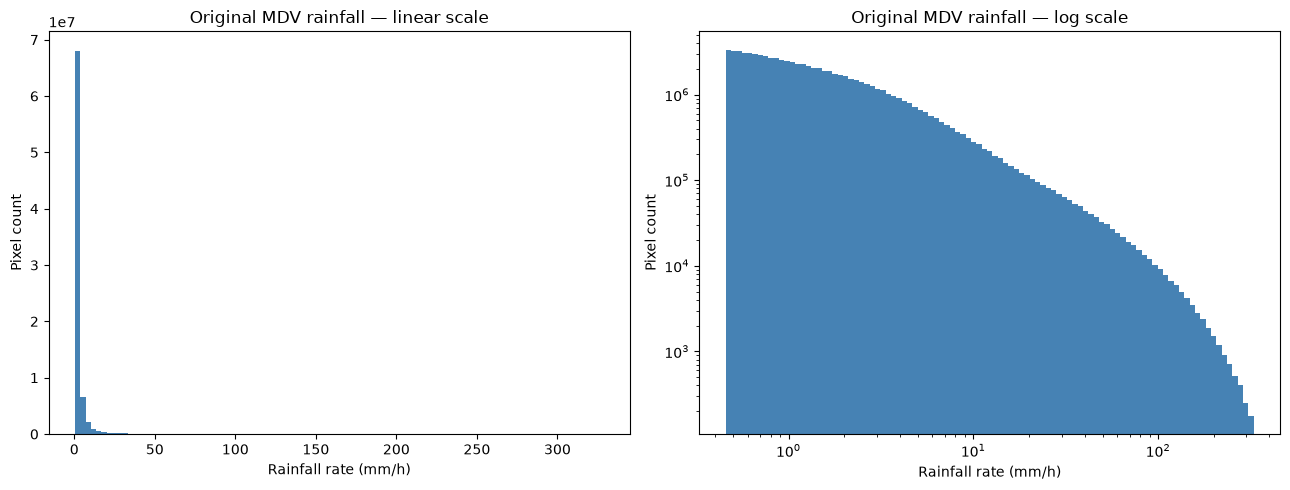

In [35]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import pyart
import re

# --------------------------------------------------
# SETTINGS
# --------------------------------------------------

base_dir = Path(
    "/Users/matthewwright/Downloads/single_precip_sample"
)

VAR = "rate"

date_re = re.compile(r"^\d{8}$")
file_re = re.compile(r"^\d{6}\.mdv$")

# None = process all available days
# Or specify dates, e.g. {"20190206", "20190227"}
RETRY_DAYS = None

# --------------------------------------------------
# FIND ORIGINAL MDV FILES
# --------------------------------------------------

day_dirs = sorted(
    d for d in base_dir.iterdir()
    if d.is_dir()
    and date_re.match(d.name)
    and (RETRY_DAYS is None or d.name in RETRY_DAYS)
)

files = sorted(
    f
    for d in day_dirs
    for f in d.iterdir()
    if f.is_file()
    and not f.name.startswith("._")
    and file_re.match(f.name)
)

print(f"Found {len(day_dirs)} daily directories")
print(f"Found {len(files)} MDV files")

# --------------------------------------------------
# READ MDV RAINFALL
# --------------------------------------------------

rain_values = []

total_pixels = 0
total_valid = 0
total_masked = 0
total_zero = 0
total_positive = 0
total_negative = 0

bad_files = []

for i, f in enumerate(files):

    try:
        radar = pyart.io.read_grid_mdv(
            f,
            file_field_names=True
        )

        raw = np.ma.asarray(
            radar.fields[VAR]["data"][0]
        )

        total_pixels += raw.size

        # Count masked pixels separately
        mask = np.ma.getmaskarray(raw)
        total_masked += np.sum(mask)

        # Extract unmasked, finite values
        values = raw.compressed()
        valid = values[np.isfinite(values)]

        total_valid += valid.size
        total_zero += np.sum(valid == 0)
        total_positive += np.sum(valid > 0)
        total_negative += np.sum(valid < 0)

        positive = valid[valid > 0]

        if positive.size:
            rain_values.append(positive)

    except Exception as e:
        bad_files.append((str(f), str(e)))
        print(f"BAD FILE: {f.name}: {e}")

    if (i + 1) % 100 == 0:
        print(f"Processed {i + 1}/{len(files)} files")

# --------------------------------------------------
# COMBINE POSITIVE RAINFALL VALUES
# --------------------------------------------------

rain_values = (
    np.concatenate(rain_values)
    if rain_values
    else np.array([])
)

# --------------------------------------------------
# STATISTICS
# --------------------------------------------------

print("\nORIGINAL MDV RAINFALL STATISTICS")
print("--------------------------------------")
print(f"Total pixels:     {total_pixels:,}")
print(f"Valid pixels:     {total_valid:,}")
print(f"Masked pixels:    {total_masked:,}")
print(f"Zero pixels:      {total_zero:,}")
print(f"Positive pixels:  {total_positive:,}")
print(f"Negative pixels:  {total_negative:,}")
print(f"Bad files:        {len(bad_files):,}")

if total_valid:
    print(
        f"Fraction positive among valid: "
        f"{100 * total_positive / total_valid:.3f}%"
    )

if total_pixels:
    print(
        f"Fraction masked: "
        f"{100 * total_masked / total_pixels:.3f}%"
    )

if rain_values.size:

    print("\nPOSITIVE RAINFALL STATISTICS")
    print("--------------------------------------")
    print(f"Minimum positive: {rain_values.min():.6f}")
    print(f"Mean positive:    {rain_values.mean():.6f}")
    print(f"Median positive:  {np.median(rain_values):.6f}")
    print(f"95th percentile:  {np.percentile(rain_values, 95):.6f}")
    print(f"99th percentile:  {np.percentile(rain_values, 99):.6f}")
    print(f"Maximum:          {rain_values.max():.6f}")

# --------------------------------------------------
# HISTOGRAMS
# --------------------------------------------------

if rain_values.size:

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    # Linear histogram
    axes[0].hist(
        rain_values,
        bins=100,
        color="steelblue",
        edgecolor="none"
    )

    axes[0].set_xlabel("Rainfall rate (mm/h)")
    axes[0].set_ylabel("Pixel count")
    axes[0].set_title("Original MDV rainfall — linear scale")

    # Logarithmic histogram
    min_rain = rain_values.min()
    max_rain = rain_values.max()

    if min_rain < max_rain:
        log_bins = np.logspace(
            np.log10(min_rain),
            np.log10(max_rain),
            100
        )
    else:
        log_bins = np.array([
            min_rain * 0.9,
            max_rain * 1.1
        ])

    axes[1].hist(
        rain_values,
        bins=log_bins,
        color="steelblue",
        edgecolor="none"
    )

    axes[1].set_xscale("log")
    axes[1].set_yscale("log")
    axes[1].set_xlabel("Rainfall rate (mm/h)")
    axes[1].set_ylabel("Pixel count")
    axes[1].set_title("Original MDV rainfall — log scale")

    plt.tight_layout()
    plt.show()

else:
    print("\nNo positive rainfall values found.")

In [36]:
from pathlib import Path
import numpy as np
import pandas as pd
import pyart
import re

# --------------------------------------------------
# SETTINGS
# --------------------------------------------------

base_dir = Path(
    "/Volumes/Rain/LiCie/projDir/data/mdv/precip/single"
)

N_FILES = 5

# --------------------------------------------------
# FIND FIRST 5 MDV FILES
# --------------------------------------------------

files = sorted(
    f
    for day_dir in base_dir.iterdir()
    if day_dir.is_dir()
    and re.fullmatch(r"\d{8}", day_dir.name)
    for f in day_dir.iterdir()
    if f.is_file()
    and re.fullmatch(r"\d{6}\.mdv", f.name)
)[:N_FILES]

print(f"Found {len(files)} MDV files to inspect")

# --------------------------------------------------
# INSPECT EACH FILE AND FIELD
# --------------------------------------------------

results = []

for f in files:

    print("\n" + "=" * 75)
    print("FILE:", f)
    print("Size:", f.stat().st_size, "bytes")

    try:
        radar = pyart.io.read_grid_mdv(
            f,
            file_field_names=True
        )

        print("Available fields:", list(radar.fields.keys()))

        for field_name, field in radar.fields.items():

            raw = np.ma.asarray(field["data"])

            mask = np.ma.getmaskarray(raw)
            values = raw.compressed()
            finite = values[np.isfinite(values)]

            result = {
                "file": f.name,
                "field": field_name,
                "shape": str(raw.shape),
                "total_pixels": raw.size,
                "masked_fraction": mask.mean(),
                "finite_pixels": finite.size,
                "zero_pixels": int(np.sum(finite == 0)),
                "positive_pixels": int(np.sum(finite > 0)),
                "negative_pixels": int(np.sum(finite < 0)),
                "min": float(finite.min()) if finite.size else np.nan,
                "max": float(finite.max()) if finite.size else np.nan,
                "mean": float(finite.mean()) if finite.size else np.nan,
            }

            results.append(result)

            print(f"\nFIELD: {field_name}")
            print("  Shape:", raw.shape)
            print(f"  Masked: {100 * mask.mean():.2f}%")
            print("  Finite pixels:", finite.size)
            print("  Zero pixels:", result["zero_pixels"])
            print("  Positive pixels:", result["positive_pixels"])
            print("  Minimum:", result["min"])
            print("  Maximum:", result["max"])

            print("  Metadata:")
            for key, value in field.items():
                if key != "data":
                    print(f"    {key}: {value}")

    except Exception as e:
        print("ERROR:", type(e).__name__, str(e))

# --------------------------------------------------
# SUMMARY TABLE
# --------------------------------------------------

summary = pd.DataFrame(results)

print("\n" + "=" * 75)
print("SUMMARY OF FIRST 5 MDV FILES")
print("=" * 75)

if not summary.empty:
    display(summary)
else:
    print("No readable fields found.")

Found 5 MDV files to inspect

FILE: /Volumes/Rain/LiCie/projDir/data/mdv/precip/single/19700101/000956.mdv
Size: 9456 bytes
Available fields: ['precip', 'rate']

FIELD: precip
  Shape: (1, 800, 800)
  Masked: 99.99%
  Finite pixels: 35
  Zero pixels: 35
  Positive pixels: 0
  Minimum: 0.0
  Maximum: 0.0
  Metadata:
    _FillValue: -9999.0

FIELD: rate
  Shape: (1, 800, 800)
  Masked: 99.99%
  Finite pixels: 35
  Zero pixels: 35
  Positive pixels: 0
  Minimum: 0.0
  Maximum: 0.0
  Metadata:
    _FillValue: -9999.0

FILE: /Volumes/Rain/LiCie/projDir/data/mdv/precip/single/19700101/001240.mdv
Size: 9060 bytes
Available fields: ['precip', 'rate']

FIELD: precip
  Shape: (1, 800, 800)
  Masked: 100.00%
  Finite pixels: 4
  Zero pixels: 4
  Positive pixels: 0
  Minimum: 0.0
  Maximum: 0.0
  Metadata:
    _FillValue: -9999.0

FIELD: rate
  Shape: (1, 800, 800)
  Masked: 100.00%
  Finite pixels: 4
  Zero pixels: 4
  Positive pixels: 0
  Minimum: 0.0
  Maximum: 0.0
  Metadata:
    _FillValue: -

,file,field,shape,total_pixels,masked_fraction,finite_pixels,zero_pixels,positive_pixels,negative_pixels,min,max,mean
0,000956.mdv,precip,"(1, 800, 800)",640000,0.999945,35,35,0,0,0.0,0.0,0.0
1,000956.mdv,rate,"(1, 800, 800)",640000,0.999945,35,35,0,0,0.0,0.0,0.0
2,001240.mdv,precip,"(1, 800, 800)",640000,0.999994,4,4,0,0,0.0,0.0,0.0
3,001240.mdv,rate,"(1, 800, 800)",640000,0.999994,4,4,0,0,0.0,0.0,0.0
4,001757.mdv,precip,"(1, 800, 800)",640000,0.999897,66,66,0,0,0.0,0.0,0.0
5,001757.mdv,rate,"(1, 800, 800)",640000,0.999897,66,66,0,0,0.0,0.0,0.0
6,001758.mdv,precip,"(1, 800, 800)",640000,1.000000,0,0,0,0,NaN,NaN,NaN
7,001758.mdv,rate,"(1, 800, 800)",640000,1.000000,0,0,0,0,NaN,NaN,NaN
8,002644.mdv,precip,"(1, 800, 800)",640000,0.999969,20,20,0,0,0.0,0.0,0.0
9,002644.mdv,rate,"(1, 800, 800)",640000,0.999969,20,20,0,0,0.0,0.0,0.0


## Interpretation checklist

- **Synthetic tests pass:** overlap matrix and reshaping are behaving as intended.
- **Real-data valid-overlap conservation passes:** the sparse remapping preserves the projected-area integral over contributing overlap.
- **Full-target integral differs:** usually due to partial spatial coverage, missing data, or extrapolation-by-renormalisation; inspect coverage map.
- **Pixel means differ:** not necessarily an error; grids have different cell sizes and extents.
- **Negative or extreme rainfall rates:** inspect source data and its missing-value conventions.
- **Projection mismatch:** stop. Matching x/y numerical ranges alone is not proof of matching CRS.
- **6-hour output:** use the optional section for a sanity check, not a one-snapshot conservation comparison.

When ready, run the full script on Mac using a single day and one worker, then inspect the resulting 6-hour file here.